# ST1519 Agile MLOps CA1 — PBI 02: Decision Tree Fraud Model

**Runs:** `DT_safe` (production-eligible) and `DT_full` (exploratory leakage check)

## 1. Model Objective

Predict whether an SP-buy order is **fraud** (`is_fraud = 1`) using information available when the order is assessed.
The Trust & Safety team can only review a limited number of orders, so flagged orders should be **precise**, while still catching a reasonable share of fraud (**recall**).

This notebook also checks whether the 10 uncertain customer-snapshot features in the full dataset may be leaking future information.

## 2. Algorithm Explanation and Justification

A **decision tree** asks a series of yes/no questions, such as *"Is account_age_days ≤ 120?"* and then *"Is country_code_PK = 1?"*,
until it reaches a leaf. Each leaf holds the share of fraud among the training orders that ended there, which becomes the fraud probability.
Each split is chosen to make the groups as "pure" as possible (lowest Gini impurity or entropy).

**Why a Decision Tree?**

- **Interpretable:** the rules can be read and explained to analysts.
- **Fast:** it trains in seconds on about 666,000 orders, which helps the 3-minute retraining requirement (PBI 05).
- **No scaling needed:** splits compare one feature to a value, so feature ranges do not matter.
- **Captures non-linear patterns and interactions** (for example, country combined with payment method).
- **A clear baseline** to compare against the MLP neural network.

**Main weakness:** a deep tree memorises the training data (overfitting). We control this with `max_depth` and `min_samples_leaf`.

## 3. Imports and Configuration

All training logic lives in `src/decision_tree.py` and `src/model_utils.py`.
The notebook only calls those functions, so automated retraining (PBI 05) runs the **same code** without opening this notebook:

```powershell
python src/decision_tree.py            # trains DT_safe + DT_full and logs to MLflow
```

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

# Find the repository root so "src/" can be imported (works from notebooks/ or the root)
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_split.py").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

import model_utils as mu                       # shared loading / evaluation / MLflow helpers
import decision_tree as dt                     # this notebook's model
from data_processing import SNAPSHOT_FEATURES  # team's list of 10 uncertain snapshot features
from data_split import create_split_labels      # team's shared chronological split

# ---- Configuration (no personal paths or secrets in code) ----
DATA_DIR = os.environ.get("FRAUD_DATA_DIR", REPO_ROOT / "data" / "processed")
OUTPUT_DIR = REPO_ROOT / "outputs"     # local plots/models (not committed)
RUN_SEARCH = True                      # False = skip the search and use the saved settings
LOG_TO_MLFLOW = True                   # uses $MLFLOW_TRACKING_URI, else a LOCAL mlruns/ store
DEVELOPER = mu.DEFAULT_DEVELOPER     # "emi" unless $MODEL_DEVELOPER is set

pd.set_option("display.float_format", "{:.4f}".format)
print("Repository:", REPO_ROOT)
print("Random seed:", mu.RANDOM_SEED)

Repository: /srv/MLOps_CA1_group5
Random seed: 42


## 4. Dataset Loading and Validation

Load both processed feature files from PBI 01 and check that:

- the required columns exist and `is_fraud` only contains 0 and 1
- there are no duplicate orders (`country_code` + `order_id` is the order key)
- no feature has missing or infinite values
- both files contain **exactly the same orders and labels, in the same order**

The SHA-256 checksum identifies the exact file version, so every teammate can confirm they used the same data.

In [2]:
safe_path = mu.dataset_path("safe", DATA_DIR)
full_path = mu.dataset_path("full", DATA_DIR)

df_safe = mu.load_feature_data(safe_path)   # raises an error if any check fails
df_full = mu.load_feature_data(full_path)
mu.check_same_orders(df_safe, df_full)

checksums = {"safe": mu.file_sha256(safe_path), "full": mu.file_sha256(full_path)}
pd.DataFrame({
    "rows": [len(df_safe), len(df_full)],
    "columns": [df_safe.shape[1], df_full.shape[1]],
    "features": [len(mu.get_feature_columns(df_safe)), len(mu.get_feature_columns(df_full))],
    "fraud_rate_%": [df_safe["is_fraud"].mean() * 100, df_full["is_fraud"].mean() * 100],
    "sha256": [checksums["safe"], checksums["full"]],
}, index=["safe", "full"])

,rows,columns,features,fraud_rate_%,sha256
safe,949872,36,31,10.9933,656a05ca11891816989d51eeaf4c706aab2e9b38682fdf...
full,949872,46,41,10.9933,d5abc1ac0ce107b1118a47327965b2ba1393f917a59b4f...


## 5. Feature Selection

- **Not used as inputs:** `country_code`, `order_id`, `customer_id`, `order_date` (kept for tracking and splitting) and the target `is_fraud`.
  Country is still used, through the one-hot columns `country_code_BD`, `country_code_MY`, and so on.
- **`refund_value` is never a feature.** Every fraud order has a refund of 0, so the refund is recorded *after* the fraud decision (target leakage).
- The **full** dataset has 10 extra customer-snapshot features. The customer table seems to be one snapshot taken near the end of the data (around 11 May 2023), so these values may include activity that happened **after** an order was placed.

In [3]:
safe_features = mu.get_feature_columns(df_safe)   # also checks no forbidden column is a feature
full_features = mu.get_feature_columns(df_full)
extra_features = [f for f in full_features if f not in safe_features]

print("Safe features:", len(safe_features))
print("Full features:", len(full_features))
print("Extra features in full = SNAPSHOT_FEATURES:", sorted(extra_features) == sorted(SNAPSHOT_FEATURES))
print("refund_value in either dataset:", "refund_value" in df_safe.columns or "refund_value" in df_full.columns)
print("\nExtra (snapshot) features:", extra_features)

Safe features: 31
Full features: 41
Extra features in full = SNAPSHOT_FEATURES: True
refund_value in either dataset: False

Extra (snapshot) features: ['cancel_rate', 'refund_rate', 'avg_payment_per_order', 'mobile_verified', 'associated_capped', 'log_num_orders_last_50days', 'log_num_cancelled_orders_last_50days', 'log_num_refund_orders_last_50days', 'log_total_payment_last_50days', 'log_num_associated_customers']


## 6. Shared Chronological Split

We reuse `create_split_labels()` from `src/data_split.py`, so every teammate and both datasets use **the same orders**:

- **Train:** up to 15 Mar 2023, used to fit the model
- **Validation:** 16 Mar to 13 Apr 2023, used to choose hyperparameters and the decision threshold
- **Test:** from 14 Apr 2023, used only once for the final scores

The split is by date, not random, because the model will be used on *future* orders.
A random split would let the model learn from orders that happen after the ones it is tested on.

In [4]:
split = create_split_labels(df_safe)
assert split.equals(create_split_labels(df_full)), "Safe and full splits differ!"

split_summary = (df_safe.assign(split=split)
                 .groupby("split")
                 .agg(first_date=("order_date", "min"), last_date=("order_date", "max"),
                      orders=("is_fraud", "size"), fraud_orders=("is_fraud", "sum"),
                      fraud_rate=("is_fraud", "mean"))
                 .loc[["Train", "Validation", "Test"]])
split_summary["share_%"] = split_summary["orders"] / len(df_safe) * 100
split_summary

,first_date,last_date,orders,fraud_orders,fraud_rate,share_%
split,,,,,,
Train,2022-11-12,2023-03-15,665876,67594,0.1015,70.1017
Validation,2023-03-16,2023-04-13,139874,18993,0.1358,14.7256
Test,2023-04-14,2023-05-11,144122,17835,0.1237,15.1728


## 7. Class Imbalance Analysis

Only about 1 in 9 orders is fraud. A model that always predicts "not fraud" would score about 89% accuracy while catching **no** fraud.
That is why we focus on **precision, recall, F1 and average precision** for the fraud class, not on accuracy.

The fraud rate is also **higher in later periods** (10.2% in train, 13.6% in validation, 12.4% in test), so the data changes over time.

In [5]:
for name in ["Train", "Validation", "Test"]:
    y = df_safe.loc[split == name, "is_fraud"]
    print(f"{name:<11} not fraud: {(y == 0).sum():>7,}   fraud: {(y == 1).sum():>6,}   "
          f"fraud %: {y.mean() * 100:5.2f}   ratio: {(y == 0).sum() / (y == 1).sum():.1f} : 1")

Train       not fraud: 598,282   fraud: 67,594   fraud %: 10.15   ratio: 8.9 : 1
Validation  not fraud: 120,881   fraud: 18,993   fraud %: 13.58   ratio: 6.4 : 1
Test        not fraud: 126,287   fraud: 17,835   fraud %: 12.37   ratio: 7.1 : 1


## 8. Hyperparameter Selection

We use a small search of 24 trees (each takes a few seconds), trained on **safe Train** and scored on **safe Validation**. The test set is not used.

| Hyperparameter | Values tried | Why |
|---|---|---|
| `criterion` | gini, entropy | Two ways to measure split quality |
| `max_depth` | 6, 10, 14 | Limits how many questions the tree can ask (controls overfitting) |
| `min_samples_leaf` | 50, 200 | Each leaf needs enough orders for a reliable fraud rate |
| `class_weight` | None, balanced | Does giving fraud orders more weight help with the imbalance? |
| `min_samples_split` | fixed at 100 | Mostly redundant once `min_samples_leaf` is set |
| `random_state` | 42 | Reproducibility |

**Ranking metric: validation average precision.** It does not depend on a threshold and is suited to imbalanced data.

In [6]:
if RUN_SEARCH:
    tuning_table, params = dt.tune(df_safe)
    if LOG_TO_MLFLOW:
        mu.log_tuning_table(tuning_table, "decision_tree_tuning", developer=DEVELOPER)
    display(tuning_table.head(12))
else:
    params = dt.SELECTED_PARAMS

print("Selected hyperparameters:", params)
print("Same as SELECTED_PARAMS saved in src/decision_tree.py:", params == dt.SELECTED_PARAMS)

[MLflow] No shared server configured -> LOCAL testing store: sqlite:////srv/MLOps_CA1_group5/mlruns/mlflow.db


2026/11/25 10:51:10 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/25 10:51:10 INFO mlflow.store.db.utils: Updating database tables


,criterion,max_depth,min_samples_leaf,class_weight,val_average_precision,val_roc_auc,train_average_precision,depth,leaves,train_seconds
0,entropy,10,50,None,0.5160,0.8452,0.4376,10,472,3.7500
1,gini,10,50,None,0.5147,0.8443,0.4369,10,472,3.5000
2,gini,14,200,balanced,0.5142,0.8446,0.4411,14,1024,4.8700
3,entropy,14,50,None,0.5141,0.8383,0.4653,14,1759,5.3000
4,entropy,14,200,balanced,0.5141,0.8449,0.4418,14,1042,5.5700
5,gini,14,200,None,0.5138,0.8447,0.4423,14,807,4.2500
6,entropy,14,200,None,0.5136,0.8439,0.4430,14,890,5.1000
7,gini,14,50,None,0.5115,0.8378,0.4644,14,1675,4.4700
8,entropy,14,50,balanced,0.5102,0.8377,0.4598,14,1836,5.3500
9,entropy,10,200,None,0.5101,0.8453,0.4294,10,320,3.8800


Selected hyperparameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 100, 'min_samples_leaf': 50, 'class_weight': None, 'random_state': 42}
Same as SELECTED_PARAMS saved in src/decision_tree.py: True


**Reading the search results**

- Depth 6 is clearly worse (it underfits). Depths 10 and 14 are very close, and the top results differ by only about 0.003 AP.
  We keep the **simpler depth-10 tree** that came first.
- **`class_weight="balanced"` did not improve validation AP.** Weighting shifts the predicted probabilities,
  but we choose the decision threshold on validation data anyway, so the imbalance is handled there.
- Validation AP (about 0.52) is *higher* than training AP (about 0.44) because AP depends on the fraud rate, which is higher in validation.
  Comparing AP across periods with different fraud rates must be done with care.

## 9. Safe Dataset Training (DT_safe)

`mu.run_training()` does the same steps for every run:

1. Split with the shared chronological function.
2. Train on **Train** only.
3. Choose the decision threshold that gives the best fraud F1 on **Validation**.
4. Score **Test** once with that threshold.
5. Save plots and the model locally, and log everything to MLflow.

`DT_safe` is the **production-eligible** run.

In [7]:
mlflow_location = mu.setup_mlflow() if LOG_TO_MLFLOW else None
common = dict(output_dir=OUTPUT_DIR, mlflow_location=mlflow_location, developer=DEVELOPER,
              snapshot_features=SNAPSHOT_FEATURES, trusted_types=dt.TRUSTED_TYPES)

result_safe, model_safe = mu.run_training(
    dt.ALGORITHM, dt.SHORT_NAME, "safe", df_safe, dt.train_model, params,
    dt.feature_importance, dataset_sha256=checksums["safe"], **common)

print(f"Threshold chosen on validation: {result_safe['threshold']:.4f}")
print(f"Training time: {result_safe['train_seconds']:.1f} s")
print("Extra training info:", result_safe["extra_metrics"])

[MLflow] No shared server configured -> LOCAL testing store: sqlite:////srv/MLOps_CA1_group5/mlruns/mlflow.db


2026/11/25 10:51:22 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Threshold chosen on validation: 0.1400
Training time: 3.9 s
Extra training info: {'tree_depth': 10.0, 'tree_leaves': 472.0}


## 10. Full Dataset Training (DT_full)

Same hyperparameters, seed, split, preprocessing **and the same threshold** as `DT_safe`.
The **only** difference is the 10 extra snapshot features, so any change in results comes from them.

This run is tagged `exploratory=true` and `production_eligible=false` in MLflow. It must never be registered or promoted.

In [8]:
result_full, model_full = mu.run_training(
    dt.ALGORITHM, dt.SHORT_NAME, "full", df_full, dt.train_model, params,
    dt.feature_importance, threshold=result_safe["threshold"],   # reuse the safe threshold
    dataset_sha256=checksums["full"], **common)

print(f"Threshold reused: {result_full['threshold']:.4f}")
print(f"Training time: {result_full['train_seconds']:.1f} s")

2026/11/25 10:51:33 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Threshold reused: 0.1400
Training time: 7.3 s


## 11. Model Evaluation

Results on the **test** period (14 Apr to 11 May 2023), which was not used for any decision.

- **Precision:** of the orders we flag, how many are really fraud (analysts' time is not wasted)
- **Recall:** of all fraud orders, how many we catch
- **Average precision (AP):** summarises the whole precision-recall curve without needing a threshold.
  A random model would score about equal to the fraud rate (about 0.12 here).

In [9]:
results = [result_safe, result_full]
comparison = mu.comparison_table(results)
comparison

,DT_safe,DT_full
Accuracy,0.8056,0.8401
Precision (fraud),0.3524,0.4162
Recall (fraud),0.6821,0.7252
F1 (fraud),0.4648,0.5289
Average precision,0.4173,0.4536
ROC-AUC,0.8031,0.8592
TP,12166,12934
FP,22354,18141
FN,5669,4901
TN,103933,108146


DT_safe


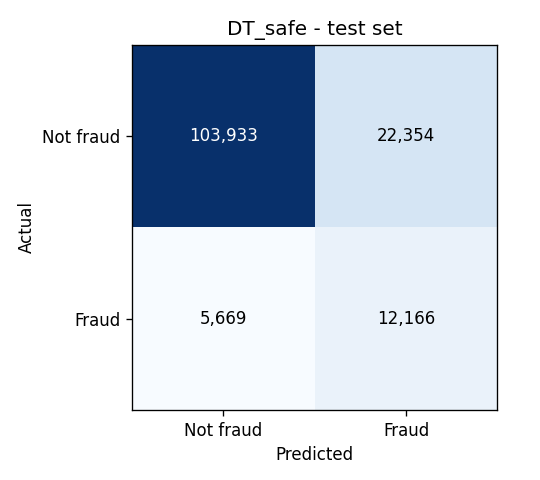

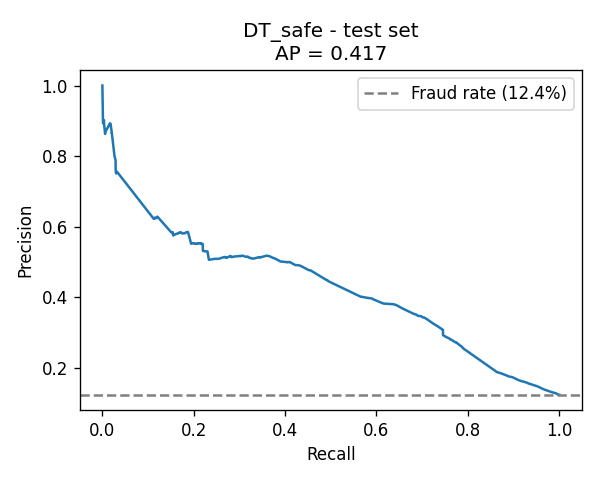

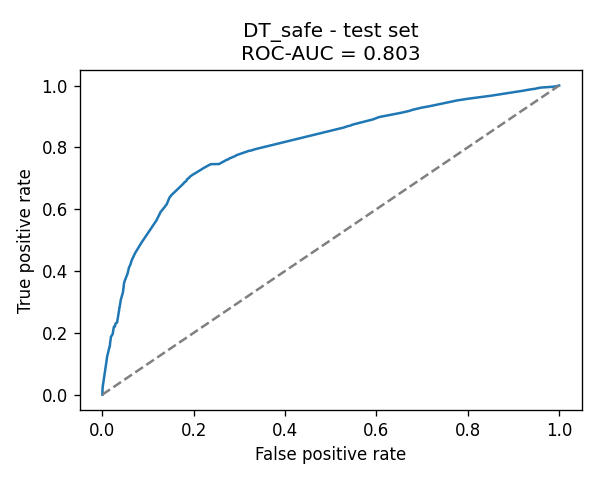

DT_full


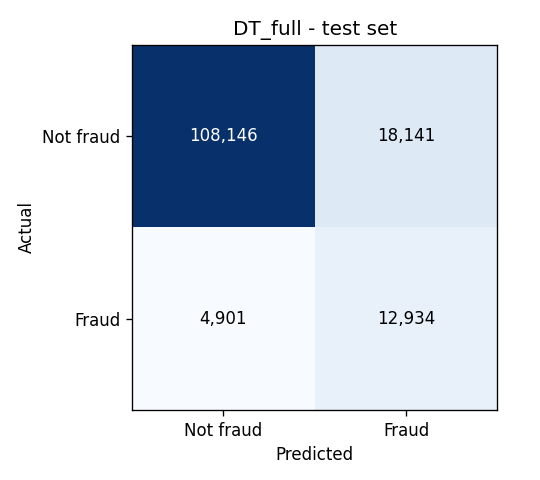

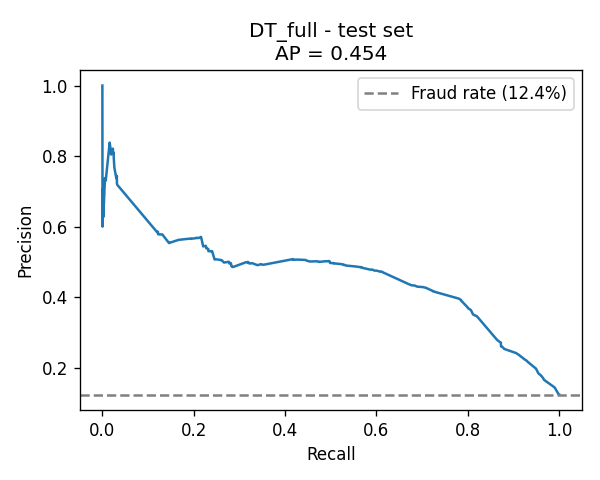

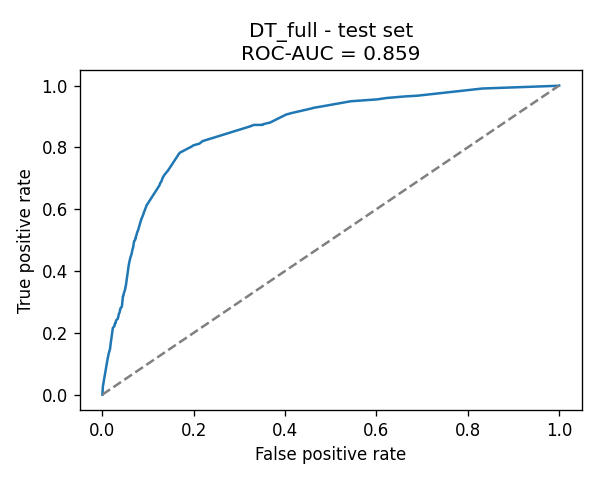

In [10]:
for run in ["DT_safe", "DT_full"]:
    plots = OUTPUT_DIR / run / "plots"
    print(run)
    display(Image(plots / "confusion_matrix_test.png"), Image(plots / "precision_recall_test.png"),
            Image(plots / "roc_test.png"))

## 12. Safe versus Full Comparison

In [11]:
metrics = ["Precision (fraud)", "Recall (fraud)", "F1 (fraud)", "Average precision", "ROC-AUC", "Train seconds"]
diff = comparison.loc[metrics].T.astype(float).T
diff["full - safe"] = diff.iloc[:, 1] - diff.iloc[:, 0]
diff["validation AP (safe / full)"] = [""] * len(diff)
diff.loc["Average precision", "validation AP (safe / full)"] = (
    f"{result_safe['validation']['average_precision']:.4f} / {result_full['validation']['average_precision']:.4f}")
display(diff)

ax = comparison.loc[metrics[:-1]].astype(float).plot.bar(figsize=(8, 4), rot=0)
ax.set_title("Test-set metrics: safe vs full features")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

,DT_safe,DT_full,full - safe,validation AP (safe / full)
Precision (fraud),0.3524,0.4162,0.0638,
Recall (fraud),0.6821,0.7252,0.0431,
F1 (fraud),0.4648,0.5289,0.0641,
Average precision,0.4173,0.4536,0.0363,0.5160 / 0.5233
ROC-AUC,0.8031,0.8592,0.0561,
Train seconds,3.8707,7.2501,3.3794,


## 13. Potential Data Leakage Analysis

A higher score with the full features does **not** prove leakage. Those features might simply be useful.
A more informative check is to look at **when** the extra features help.

If the customer snapshot was taken around 11 May 2023, its "last 50 days" window covers about 22 March to 11 May.
For orders in that window, the snapshot may already count the order itself and what happened afterwards.
If the snapshot features leak, their advantage should **grow for orders closer to the snapshot date**.

The table uses only months the models never trained on (after 15 March).

In [12]:
by_month = mu.gain_by_month(model_safe, model_full, df_safe, df_full)
display(by_month)

ax = by_month.plot(x="month", y="gain_full_minus_safe", kind="bar", legend=False, rot=0, figsize=(6, 3.5))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("AP gain (full - safe)")
ax.set_title("Extra benefit of snapshot features by month")
plt.tight_layout()
plt.show()

,month,orders,fraud_rate_%,safe_AP,full_AP,gain_full_minus_safe
0,2023-03,77691,13.9400,0.5425,0.5375,-0.0050
1,2023-04,148855,12.6100,0.4338,0.4602,0.0263
2,2023-05,57450,12.5700,0.4445,0.4877,0.0432


**Interpretation (values from the run in this notebook)**

| Month (unseen) | DT gain from snapshot features |
|---|---|
| March (16th to 31st) | about −0.005 (no benefit) |
| April | about +0.026 |
| May (1st to 11th) | about +0.043 |

The snapshot features give **no benefit for the earliest unseen orders**, and their advantage **grows as orders approach the presumed snapshot date**.
This pattern is **consistent with** temporal leakage.
It is **not proof**: the fraud pattern itself also changes over time, and the snapshot date cannot be confirmed.
Either way, we cannot show these features would be available when a real order is assessed, so they stay **excluded from production**.

## 14. Feature Importance

A Decision Tree's built-in importance measures how much each feature reduces impurity across all its splits.
Red bars are snapshot features. Importance shows what the model **relies on**, but it does not by itself prove leakage.

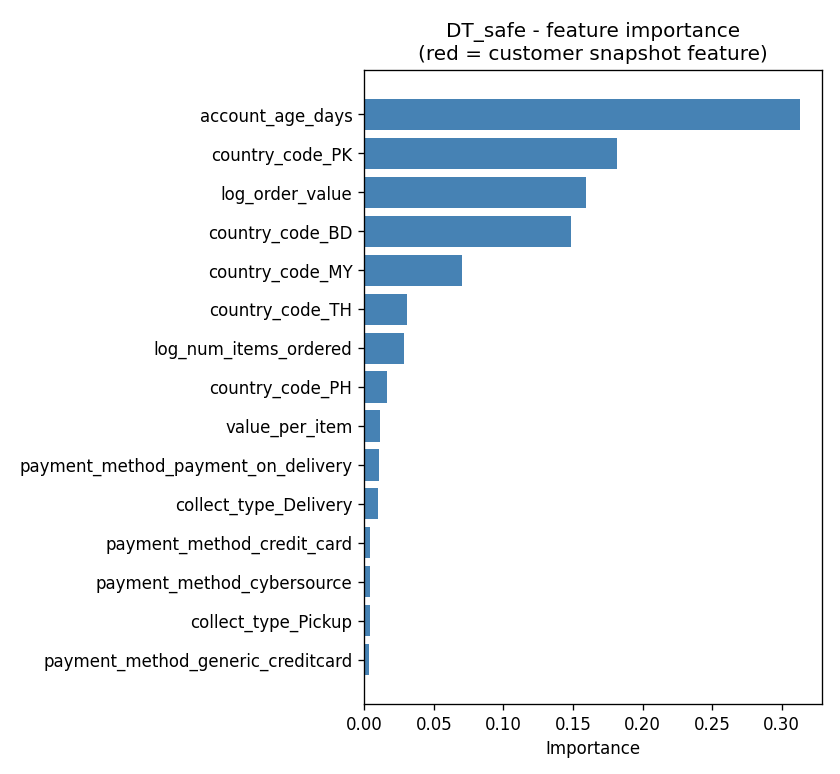

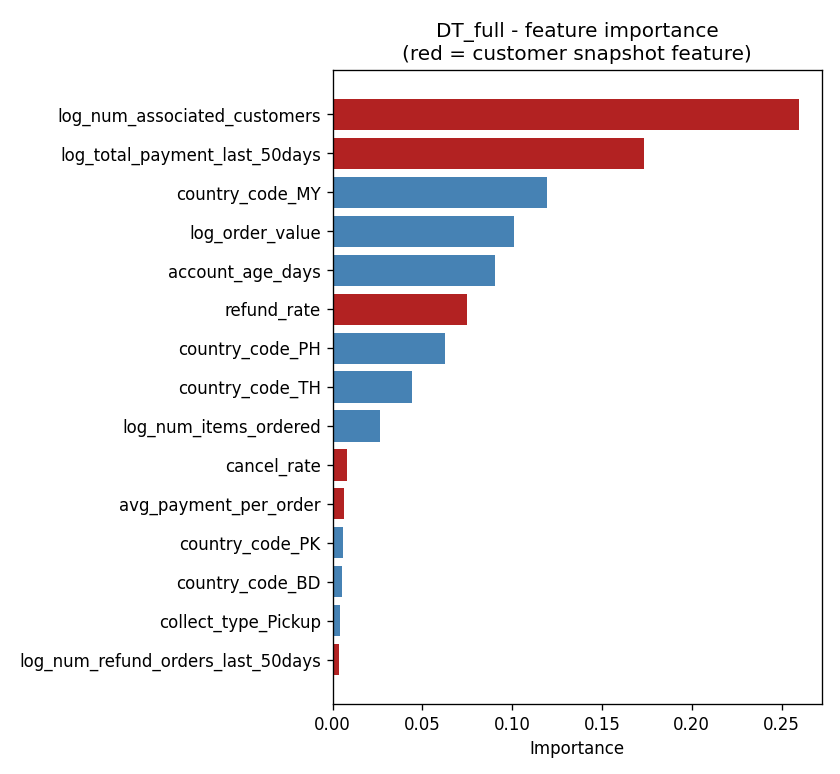

Share of DT_full importance from snapshot features: 53.0%


In [13]:
for run in ["DT_safe", "DT_full"]:
    display(Image(OUTPUT_DIR / run / "plots" / "feature_importance.png"))

snapshot_share = result_full["importance"].query("feature in @SNAPSHOT_FEATURES")["importance"].sum()
print(f"Share of DT_full importance from snapshot features: {snapshot_share:.1%}")

**The first three levels of the DT_safe tree**: the rules an analyst could read.

In [14]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(model_safe, max_depth=2, feature_names=safe_features, class_names=["not fraud", "fraud"],
          filled=True, proportion=True, impurity=False, fontsize=8, ax=ax)
plt.title("DT_safe - first three levels")
plt.show()

## 15. MLflow Experiment Tracking

Logging uses the team's shared **`src/mlflow_utils.py`** (#38): `start_model_run`, `log_model_parameters`,
`log_classification_metrics`, `log_evaluation_artifacts` and `log_trained_model`. Experiment **`SP-buy-Fraud-Detection`**,
run names **`{member}_{algorithm}_{dataset_version}_{model_version}`** (e.g. `emi_decision_tree_safe_v1`, `emi_mlp_full_v1`),
and metric names `val_*` / `test_*` (`pr_auc` = average precision).

Each run logs:

- **Tags:** `team_member`, `algorithm`, `dataset_version`, `model_version`, `production_eligible`, `exploratory`, `tracking_location`
- **Parameters:** hyperparameters, seed, dataset SHA-256, feature count, train/validation/test row counts, `decision_threshold`
- **Metrics:** validation and test metrics, TP/TN/FP/FN, training and inference time
- **Artifacts:** confusion matrix, PR and ROC curves, feature importance (plot and CSV), feature list, and the model with its signature (via `log_trained_model`)

The tracking URI is read from the `MLFLOW_TRACKING_URI` environment variable, so no server address is hardcoded.
If it is not set, runs go to a **local** test store (`mlruns/`, git-ignored), tagged `tracking_location=local`.
To view local runs, run `mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db` from the repository root.

In [15]:
for r in results:
    print(f"{mu.mlflow_run_name(r):<28} run_id={r.get('mlflow_run_id', 'not logged')}  "
          f"production_eligible={r['production_eligible']}  location={mlflow_location}")

emi_decision_tree_safe_v1    run_id=7fa67d8a6fe64fed90a92cb0bdc0e478  production_eligible=True  location=local
emi_decision_tree_full_v1    run_id=35d2240640444434893f9533588eddc6  production_eligible=False  location=local


## 16. Conclusion and Limitations

**Results (test period 14 Apr to 11 May 2023, values from this notebook's run)**

| | DT_safe | DT_full |
|---|---|---|
| Average precision | 0.417 | 0.454 |
| ROC-AUC | 0.803 | 0.859 |
| Fraud precision | 0.352 | 0.416 |
| Fraud recall | 0.682 | 0.725 |
| Fraud F1 | 0.465 | 0.529 |
| Training time | about 4–5 s | about 8–9 s |
| Production eligible | **Yes** | No |

**Conclusions**

- **DT_safe is the production candidate** from this notebook. It roughly triples the fraud rate among flagged orders
  (precision 0.35 vs a base rate of 0.12) and catches about two-thirds of fraud.
- The full features improve test AP by about 0.04. They provide over half of DT_full's importance, and their benefit grows towards
  the snapshot date. This is consistent with leakage, so the team's decision to exclude them is supported (but not proven) by the results.
- Training takes seconds, so the Decision Tree fits easily in the PBI 05 retraining budget.
  The whole workflow still needs to be timed end to end on the demo laptop.

**Limitations**

- Validation AP (0.516) is noticeably higher than test AP (0.417), so performance drops on newer data (the fraud pattern drifts).
  Regular retraining (PBI 05) is important.
- The threshold maximises F1 on validation. If analysts prefer fewer false alarms, a higher threshold trades recall for precision.
  The team should agree on this rule.
- Only one train/validation/test cut was used. Results on other periods may differ.
- `account_age_days` comes from the customer table's first-order date, which is part of the same snapshot. Only 105 orders have an impossible (negative) age,
  so the risk looks low, but this feature's timing has not been formally confirmed.